In [1]:

import zipfile
import os

zip_path = "archive (7).zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("customer_churn_data")

print("Dataset extracted successfully!")


Dataset extracted successfully!


In [2]:

import os

for root, dirs, files in os.walk("customer_churn_data"):
    for file in files:
        print(os.path.join(root, file))


customer_churn_data\WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:

df = pd.read_csv(
    "customer_churn_data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:

# Number of rows and columns
print("Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Dataset information
df.info()

# Statistical summary
df.describe()


Shape: (7043, 21)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:

df.isnull().sum()


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:

(df["TotalCharges"].astype(str).str.strip() == "").sum()


np.int64(11)

In [8]:

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

print(df["TotalCharges"].isnull().sum())


11


In [9]:

df[df["TotalCharges"].isnull()][
    ["customerID", "tenure", "MonthlyCharges", "Churn"]
]


,customerID,tenure,MonthlyCharges,Churn
488,4472-LVYGI,0,52.55,No
753,3115-CZMZD,0,20.25,No
936,5709-LVOEQ,0,80.85,No
1082,4367-NUYAO,0,25.75,No
1340,1371-DWPAZ,0,56.05,No
3331,7644-OMVMY,0,19.85,No
3826,3213-VVOLG,0,25.35,No
4380,2520-SGTTA,0,20.00,No
5218,2923-ARZLG,0,19.70,No
6670,4075-WKNIU,0,73.35,No


In [10]:

df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Missing values:", df.isnull().sum().sum())


Missing values: 0


In [11]:

print("Duplicate rows:", df.duplicated().sum())

print("Duplicate IDs:",
      df["customerID"].duplicated().sum())


Duplicate rows: 0
Duplicate IDs: 0


In [12]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [13]:

df.to_csv("customer_churn_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [14]:

total_customers = df["customerID"].nunique()

print("Total Customers:", total_customers)


Total Customers: 7043


In [15]:

churned = (df["Churn"] == "Yes").sum()
retained = (df["Churn"] == "No").sum()

print("Churned Customers:", churned)
print("Retained Customers:", retained)


Churned Customers: 1869
Retained Customers: 5174


In [16]:

churn_rate = (churned / total_customers) * 100

print("Churn Rate:", round(churn_rate, 2), "%")


Churn Rate: 26.54 %


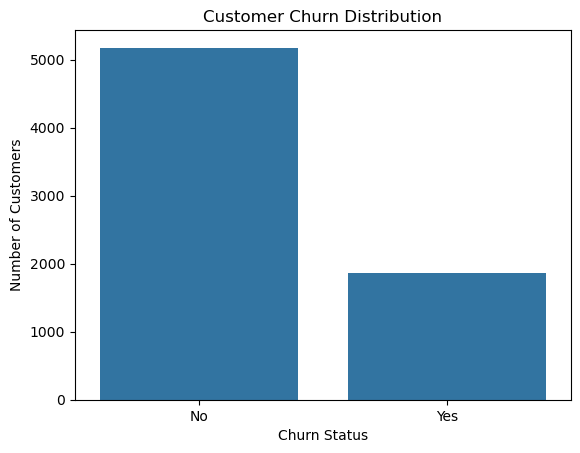

In [17]:

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.show()


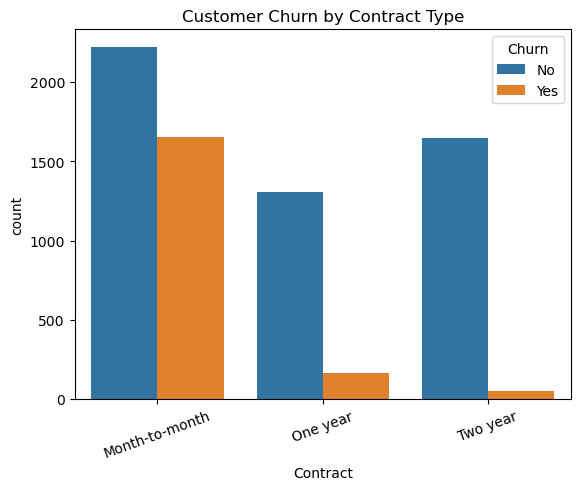

In [18]:

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xticks(rotation=20)
plt.show()


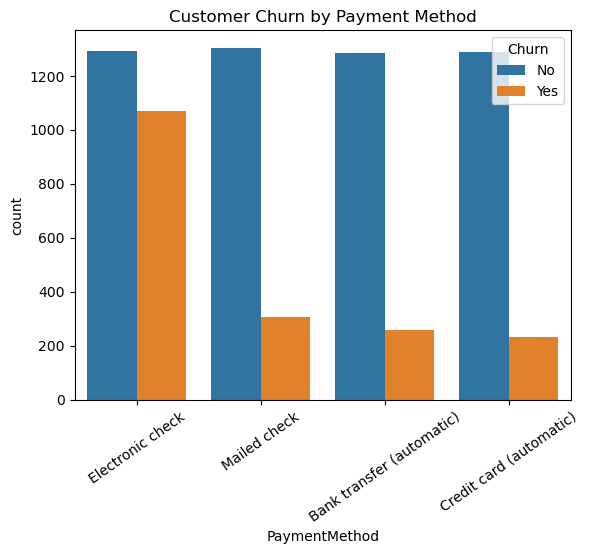

In [19]:

sns.countplot(data=df, x="PaymentMethod", hue="Churn")

plt.title("Customer Churn by Payment Method")
plt.xticks(rotation=35)
plt.show()


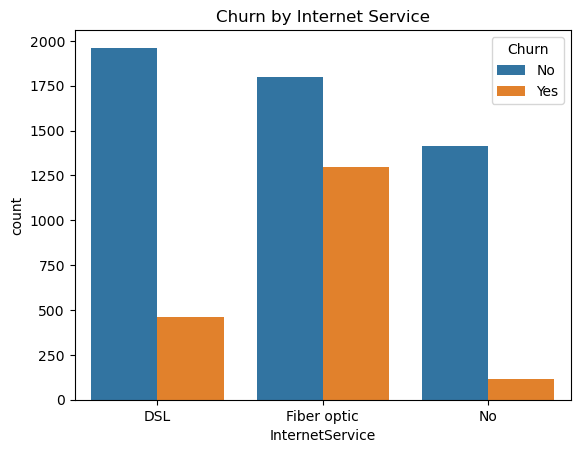

In [20]:

sns.countplot(data=df, x="InternetService", hue="Churn")

plt.title("Churn by Internet Service")
plt.show()


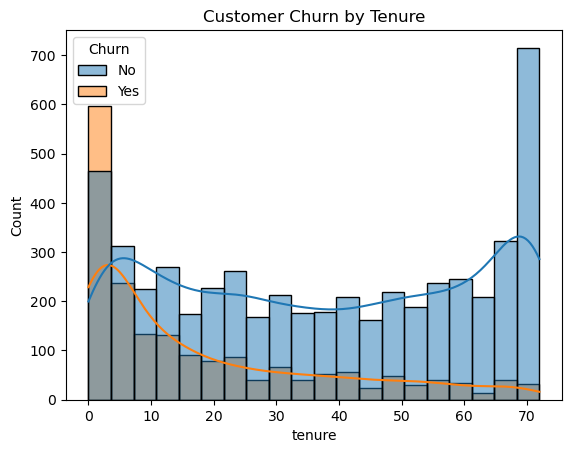

In [21]:

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=20,
    kde=True
)

plt.title("Customer Churn by Tenure")
plt.show()


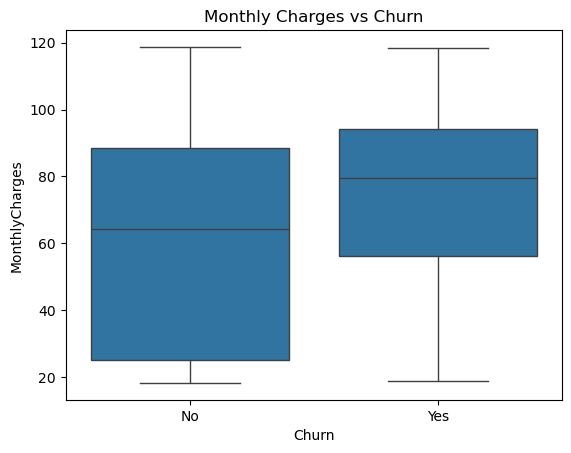

In [22]:

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Churn")
plt.show()


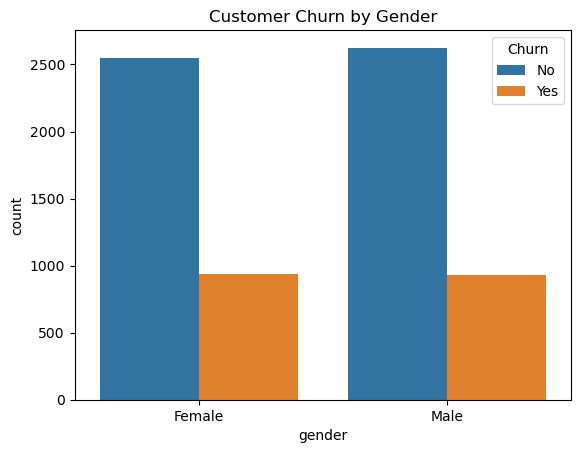

In [23]:

sns.countplot(data=df, x="gender", hue="Churn")

plt.title("Customer Churn by Gender")
plt.show()
